# Read and Plot PK Curves

Load the machine-readable dataset, select a compound/species/route/dose, and compare an individual replicate with multiple replicates on Matplotlib charts. The example uses Itraconazole in humans after IRS administration at 100 mg; edit the selection settings to explore other curves.

## 1. Install Required Packages in Notebook

Run the install cell once in the notebook's selected Python environment. The dataset is CSV, so an Excel reader is not needed.

In [ ]:
%pip install pandas numpy matplotlib

In [1]:
import importlib.metadata as metadata

for package in ("pandas", "numpy", "matplotlib"):
    print(f"{package}: {metadata.version(package)}")

pandas: 3.0.6
numpy: 2.5.4
matplotlib: 3.11.2


## 2. Import Libraries and Set Notebook Configuration

A consistent plotting style is set here for both figures.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("default")
plt.rcParams.update(
    {
        "figure.figsize": (10, 6),
        "figure.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)

## 3. Load Dataset and Confirm Renamed Columns

The path check supports running with either the workspace root or `notebook/` as the current working directory. The required headers are validated before any curve is selected.

In [3]:
DATA_FILE = "Cptimecurves_machine_readable.csv"
DATA_CANDIDATES = [
    Path.cwd() / "data" / DATA_FILE,
    Path.cwd().parent / "data" / DATA_FILE,
]
DATA_PATH = next((path.resolve() for path in DATA_CANDIDATES if path.is_file()), None)
if DATA_PATH is None:
    checked = "\n".join(str(path) for path in DATA_CANDIDATES)
    raise FileNotFoundError(f"Could not find {DATA_FILE}. Checked:\n{checked}")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} observations from {DATA_PATH}")
display(df.head())
print("Columns:", df.columns.tolist())

REQUIRED_COLUMNS = [
    "Compound",
    "Dose (mg)",
    "Dose (mg/kg)",
    "Route",
    "Species",
    "Time (h)",
    "Concentration (ng/mL)",
    "Replicate",
    "Lower bound",
    "Upper bound",
]
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required renamed columns: {missing_columns}")

Loaded 2,117 observations from C:\Users\rbachorz\Projects\httk\HTPK_workflow\httk\new_PKDB\pk-datasets\data\Cptimecurves_machine_readable.csv


,Compound,Smiles,Dose (mg),Dose (mg/kg),Route,Species,Source,Time (h),Concentration (ng/mL),Replicate,Lower bound,Upper bound,ADMET_Risk,ECCS_Class,RuleOf5,CyclPept_filter,Macrocycle,PROTAC_filter
0,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,0.00,0.000,1,0.000,0.000,4.220607,Class_2,0,0,0,0
1,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,0.25,194.730,1,116.838,311.568,4.220607,Class_2,0,0,0,0
2,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,0.50,623.136,1,506.298,739.974,4.220607,Class_2,0,0,0,0
3,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,1.00,506.298,1,389.460,623.136,4.220607,Class_2,0,0,0,0
4,32,C(O)(Cn1c2c(c(-c3cc4c(cc(OC5CC5)cc4)cc3)n1)c(n...,10.0,1.0,IRS,dog,Vidadala_2016,1.50,467.352,1,389.460,545.244,4.220607,Class_2,0,0,0,0


Columns: ['Compound', 'Smiles', 'Dose (mg)', 'Dose (mg/kg)', 'Route', 'Species', 'Source', 'Time (h)', 'Concentration (ng/mL)', 'Replicate', 'Lower bound', 'Upper bound', 'ADMET_Risk', 'ECCS_Class', 'RuleOf5', 'CyclPept_filter', 'Macrocycle', 'PROTAC_filter']


## 4. Configure Column Mapping and Curve Filters

Edit `CURVE_FILTER` to choose another compound and case. Set `Dose (mg/kg)` to a number to filter by weight-adjusted dose, or leave it as `None` to ignore that field.

In [4]:
COLUMN_MAP = {
    "x": "Time (h)",
    "y": "Concentration (ng/mL)",
    "replicate": "Replicate",
    "lower": "Lower bound",
    "upper": "Upper bound",
}
CURVE_FILTER = {
    "Compound": "Itraconazole",
    "Species": "human",
    "Route": "IRS",
    "Dose (mg)": 100,
    "Dose (mg/kg)": None,
}
SINGLE_REPLICATE = 1
MULTIPLE_REPLICATES = None  # None plots every replicate available for this curve.


def select_curve(data, filters, replicates=None):
    mask = pd.Series(True, index=data.index)
    numeric_filter_columns = {"Dose (mg)", "Dose (mg/kg)"}

    for column, value in filters.items():
        if value is None:
            continue
        if column in numeric_filter_columns:
            values = pd.to_numeric(data[column], errors="coerce")
            mask &= values.eq(float(value))
        else:
            values = data[column].astype("string").str.casefold()
            mask &= values.eq(str(value).casefold())

    selected = data.loc[mask].copy()
    if selected.empty:
        raise ValueError(f"No observations match the curve filters: {filters}")

    if replicates is not None:
        requested = [replicates] if np.isscalar(replicates) else list(replicates)
        available = set(selected[COLUMN_MAP["replicate"]].dropna().unique())
        missing = [replicate for replicate in requested if replicate not in available]
        if missing:
            raise ValueError(
                f"Requested replicate(s) {missing} are not available. "
                f"Available replicates: {sorted(available)}"
            )
        selected = selected.loc[
            selected[COLUMN_MAP["replicate"]].isin(requested)
        ].copy()

    return selected


case_data = select_curve(df, CURVE_FILTER)
available_replicates = sorted(case_data[COLUMN_MAP["replicate"]].dropna().unique())
print("Available replicates:", available_replicates)
print("Observations in selected curve:", len(case_data))

Available replicates: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Observations in selected curve: 49


## 5. Select and Plot a Single Replicate Curve

The selection guard verifies that the chosen replicate exists before plotting.

In [5]:
single_data = select_curve(df, CURVE_FILTER, replicates=[SINGLE_REPLICATE])
print(f"Single replicate {SINGLE_REPLICATE}: {len(single_data)} observations")
print("Time points:", single_data[COLUMN_MAP["x"]].nunique())
print("Missing x/y values:", single_data[[COLUMN_MAP["x"], COLUMN_MAP["y"]]].isna().sum().to_dict())

Single replicate 1: 15 observations
Time points: 15
Missing x/y values: {'Time (h)': 0, 'Concentration (ng/mL)': 0}


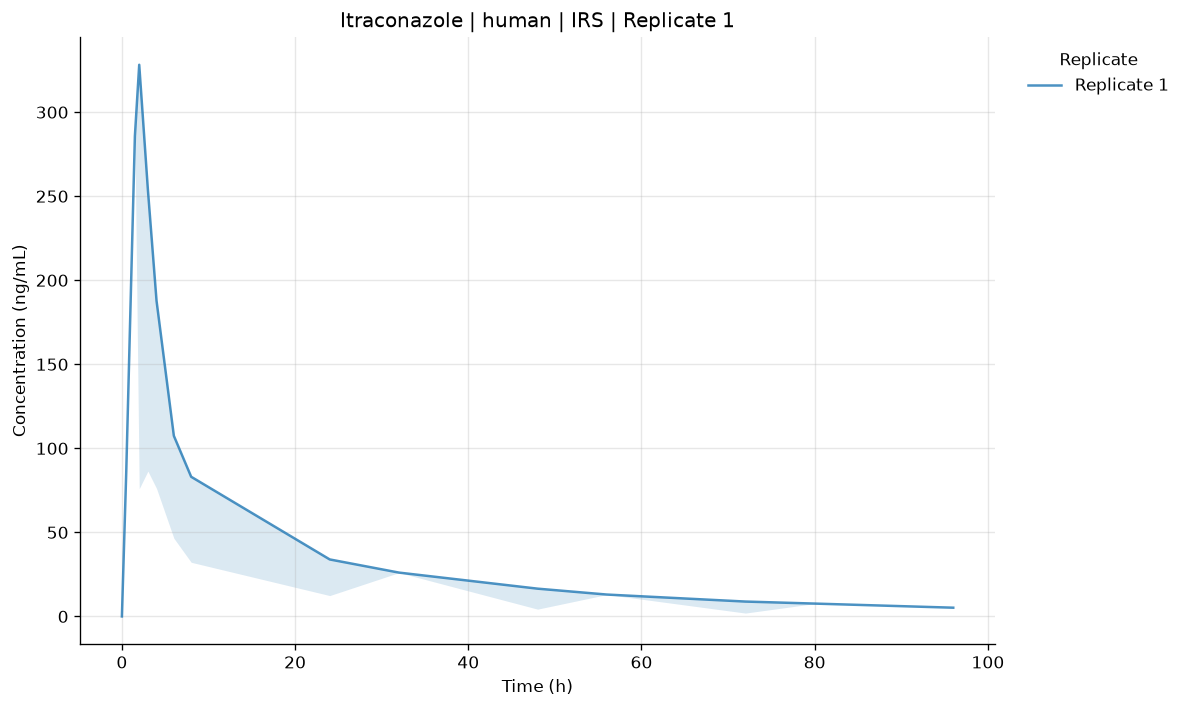

In [10]:
def plot_curves(curve_data, title, alpha=0.8, show_mean=False):
    if curve_data.empty:
        raise ValueError("Cannot plot an empty selection.")

    x_column = COLUMN_MAP["x"]
    y_column = COLUMN_MAP["y"]
    replicate_column = COLUMN_MAP["replicate"]
    replicate_ids = sorted(curve_data[replicate_column].dropna().unique())
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(replicate_ids), 1)))
    fig, ax = plt.subplots()
    clean_lines = []
    plotted_replicates = 0

    for color, replicate in zip(colors, replicate_ids):
        profile = curve_data.loc[curve_data[replicate_column].eq(replicate)].copy()
        line = pd.DataFrame(
            {
                "x": pd.to_numeric(profile[x_column], errors="coerce"),
                "y": pd.to_numeric(profile[y_column], errors="coerce"),
                "lower": pd.to_numeric(profile[COLUMN_MAP["lower"]], errors="coerce"),
                "upper": pd.to_numeric(profile[COLUMN_MAP["upper"]], errors="coerce"),
            }
        ).dropna(subset=["x", "y"]).sort_values("x")
        if line.empty:
            continue

        ax.plot(line["x"], line["y"], color=color, alpha=alpha, label=f"Replicate {replicate}")
        bounds = line.dropna(subset=["lower", "upper"])
        if not bounds.empty:
            ax.fill_between(
                bounds["x"],
                bounds["lower"],
                bounds["upper"],
                color=color,
                alpha=0.16,
                linewidth=0,
            )
        clean_lines.append(line[["x", "y"]])
        plotted_replicates += 1

    if plotted_replicates == 0:
        plt.close(fig)
        raise ValueError("The selection has no numeric time/concentration points to plot.")

    if show_mean and len(clean_lines) > 1:
        combined = pd.concat(clean_lines, ignore_index=True)
        mean_line = combined.groupby("x", as_index=False)["y"].mean().sort_values("x")
        ax.plot(mean_line["x"], mean_line["y"], color="black", linewidth=2.2, label="Mean at observed time points")

    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(title="Replicate", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    return fig, ax


single_fig, single_ax = plot_curves(
    single_data,
    title=f"{CURVE_FILTER['Compound']} | {CURVE_FILTER['Species']} | {CURVE_FILTER['Route']} | Replicate {SINGLE_REPLICATE}",
)
plt.show()

## 6. Select and Plot Multiple Replicate Curves

Leave `MULTIPLE_REPLICATES` as `None` to include every replicate in the selected case, or set it to a list such as `[1, 3]` to choose specific replicates.

,observations,time_points
Replicate,,
1,15,15
2,10,10
3,12,12
4,12,12


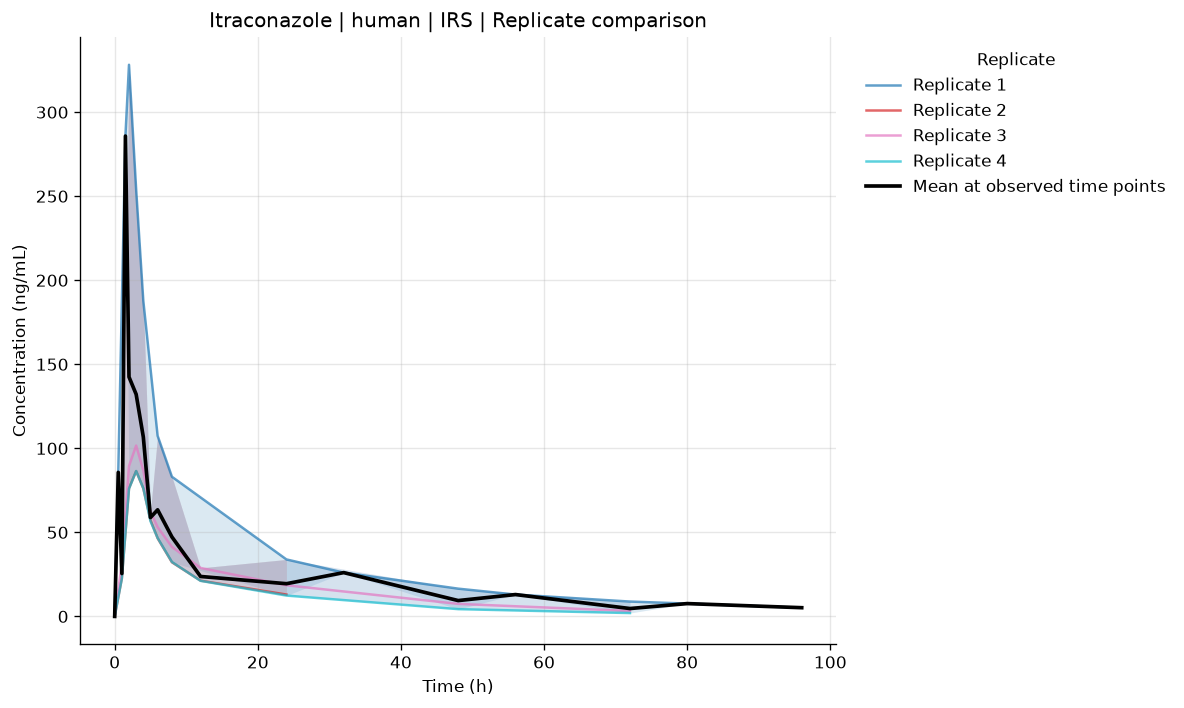

In [11]:
multiple_data = select_curve(df, CURVE_FILTER, replicates=MULTIPLE_REPLICATES)
replicate_summary = (
    multiple_data.groupby(COLUMN_MAP["replicate"])
    .agg(observations=(COLUMN_MAP["x"], "size"), time_points=(COLUMN_MAP["x"], "nunique"))
)
display(replicate_summary)

multiple_fig, multiple_ax = plot_curves(
    multiple_data,
    title=f"{CURVE_FILTER['Compound']} | {CURVE_FILTER['Species']} | {CURVE_FILTER['Route']} | Replicate comparison",
    alpha=0.7,
    show_mean=True,
)
plt.show()

## 7. Style, Label, and Validate the Matplotlib Output

Both charts use the renamed time/concentration labels, consistent replicate colors, and uncertainty bands where both bounds are available. The next cell reports missing values and duplicate replicate/time points in the plotted subsets.

In [8]:
def report_curve_quality(label, selected):
    point_columns = [COLUMN_MAP["x"], COLUMN_MAP["y"]]
    duplicate_mask = selected.duplicated(
        subset=[COLUMN_MAP["replicate"], COLUMN_MAP["x"]], keep=False
    )
    missing_xy = int(selected[point_columns].isna().any(axis=1).sum())
    print(
        f"{label}: {len(selected)} observations, "
        f"{selected[COLUMN_MAP['replicate']].nunique()} replicate(s), "
        f"{selected[COLUMN_MAP['x']].nunique()} distinct time points, "
        f"{int(duplicate_mask.sum())} rows with duplicate replicate/time, "
        f"{missing_xy} rows missing time or concentration"
    )


report_curve_quality("Single-replicate plot", single_data)
report_curve_quality("Multiple-replicate plot", multiple_data)

Single-replicate plot: 15 observations, 1 replicate(s), 15 distinct time points, 0 rows with duplicate replicate/time, 0 rows missing time or concentration
Multiple-replicate plot: 49 observations, 4 replicate(s), 18 distinct time points, 0 rows with duplicate replicate/time, 0 rows missing time or concentration


## 8. Optional: Save Figures and Export Selected Subsets

Set either option to `True` to write files under `notebook/outputs/`. Figure formats can be selected independently.

In [9]:
SAVE_FIGURES = False
EXPORT_SELECTED_SUBSETS = False
FIGURE_FORMATS = ("png", "svg")
OUTPUT_DIR = DATA_PATH.parent.parent / "notebook" / "outputs"

if SAVE_FIGURES or EXPORT_SELECTED_SUBSETS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        single_fig.savefig(
            OUTPUT_DIR / f"single_replicate.{extension}",
            bbox_inches="tight",
        )
        multiple_fig.savefig(
            OUTPUT_DIR / f"multiple_replicates.{extension}",
            bbox_inches="tight",
        )
    print(f"Figures saved in {OUTPUT_DIR}")

if EXPORT_SELECTED_SUBSETS:
    single_data.to_csv(OUTPUT_DIR / "single_replicate_data.csv", index=False)
    multiple_data.to_csv(OUTPUT_DIR / "multiple_replicates_data.csv", index=False)
    print(f"Selected data exported in {OUTPUT_DIR}")